# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Adapted from your existing exercise. Previous local outputs were cleared so new Colab runs provide their own evidence. 

Source: Original local package: 03_fastai/08_chapter4_coding_questions_and_mnist.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '03_fastai', 'fastai', '08_chapter4_coding_questions_and_mnist.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/03_fastai
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/03_fastai/results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.
- Use all 60,000 source training images with a documented validation split, all 10,000 test images and ten full-mode epochs.

- Review the labeled authored objective answers alongside genuine saved exercise outputs; prepared prose does not certify hosted execution, personal reflection or independent learner recall.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.


# Chapter 4: coding questions and further-research implementation
Source: https://github.com/fastai/fastbook/blob/master/04_mnist_basics.ipynb
Independently written answers cover the concrete coding questions: comprehensions, tensor operations, sigmoid/ReLU plots, pairwise tuples, a training loop and a small Learner. The ten-class MNIST extension uses the real MNIST dataset; smoke mode uses a stratified subset for execution checks. The labeled authored notes also address the 37 objective questionnaire prompts; these prepared answers do not certify learner recall or hosted execution.


Original: tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]]) doubled: tensor([[ 2,  4,  6],
        [ 8, 10, 12],
        [14, 16, 18]]) bottom-right: tensor([[5, 6],
        [8, 9]])


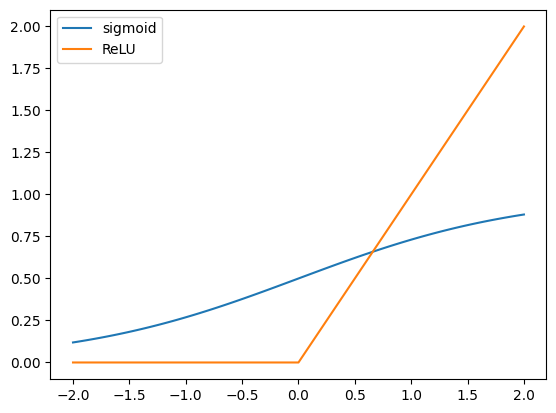

In [2]:
import os,json
from pathlib import Path
import numpy as np,pandas as pd,torch
import matplotlib.pyplot as plt
torch.manual_seed(42);torch.set_num_threads(1)
np.random.seed(42)
SMOKE=os.environ.get('COURSE_SMOKE','0')=='1'
results=Path('results');results.mkdir(exist_ok=True)

from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from sklearn.model_selection import train_test_split
odds_doubled=[2*n for n in [1,2,3,4,5] if n%2]
assert odds_doubled==[2,6,10]
matrix=torch.arange(1,10).reshape(3,3)
print('Original:',matrix,'doubled:',matrix*2,'bottom-right:',matrix[1:,1:])
def pair_items(numbers,letters):return list(zip(numbers,letters))
assert pair_items([1,2,3,4],'abcd')==[(1,'a'),(2,'b'),(3,'c'),(4,'d')]
z=torch.linspace(-2,2,101)
plt.plot(z,torch.sigmoid(z),label='sigmoid');plt.plot(z,torch.relu(z),label='ReLU');plt.legend();plt.show()
class MiniLearner:
    def __init__(self,model,train_loader,valid_loader,lr=.003):
        self.device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model=model.to(self.device);self.train_loader=train_loader;self.valid_loader=valid_loader
        self.optimizer=torch.optim.Adam(model.parameters(),lr=lr);self.history=[]
    def fit(self,epochs):
        for epoch in range(epochs):
            self.model.train();total=0.;count=0
            for x,y in self.train_loader:
                x,y=x.to(self.device),y.to(self.device)
                self.optimizer.zero_grad(set_to_none=True)
                loss=nn.functional.cross_entropy(self.model(x),y)
                loss.backward();self.optimizer.step();total+=float(loss.detach())*len(y);count+=len(y)
            self.model.eval();correct=0;size=0
            with torch.no_grad():
                for x,y in self.valid_loader:
                    x,y=x.to(self.device),y.to(self.device)
                    correct+=int((self.model(x).argmax(1)==y).sum());size+=len(y)
            self.history.append({'epoch':epoch,'training_loss':total/count,'validation_accuracy':correct/size})
        return self.history

In [3]:
data=np.load('data/mnist.npz')
if not SMOKE:
    assert len(data['x_train']) == 60000 and len(data['x_test']) == 10000, 'Full MNIST inputs required.'
xtrain,ytrain=data['x_train'],data['y_train'];xtest,ytest=data['x_test'],data['y_test']
indices=np.arange(len(xtrain))
if SMOKE:indices,_=train_test_split(indices,train_size=6000,random_state=42,stratify=ytrain)
tr,va=train_test_split(indices,test_size=.2,random_state=42,stratify=ytrain[indices])
def tensors(x,y):return torch.tensor(x/255.,dtype=torch.float32).reshape(len(x),-1),torch.tensor(y,dtype=torch.long)
train_loader=DataLoader(TensorDataset(*tensors(xtrain[tr],ytrain[tr])),batch_size=128,shuffle=True)
valid_loader=DataLoader(TensorDataset(*tensors(xtrain[va],ytrain[va])),batch_size=256)
model=nn.Sequential(nn.Linear(784,128),nn.ReLU(),nn.Linear(128,10))
learner=MiniLearner(model,train_loader,valid_loader)
history=learner.fit(3 if SMOKE else 10)
# Pixel-centroid baseline extends the chapter's binary pixel similarity to ten digits.
centroids=np.stack([xtrain[tr][ytrain[tr]==digit].mean(0).reshape(-1)/255. for digit in range(10)])
eval_idx=np.arange(2000) if SMOKE else np.arange(len(xtest))
testx,testy=tensors(xtest[eval_idx],ytest[eval_idx]);model.eval()
with torch.no_grad():pred=model(testx.to(learner.device)).argmax(1).cpu()
distance=(np.sum(testx.numpy()**2,axis=1)[:,None] - 2*testx.numpy()@centroids.T + np.sum(centroids**2,axis=1)[None,:])/784
report={'neural_accuracy':float((pred==testy).float().mean()),
 'centroid_accuracy':float(np.mean(distance.argmin(1)==ytest[eval_idx])),
 'training_rows':len(tr),'validation_rows':len(va),'source_training_rows':len(xtrain),
 'test_rows':len(eval_idx),'ten_classes':True,'smoke_run':SMOKE,'device':str(learner.device),'epochs':3 if SMOKE else 10}
print(report)
pd.DataFrame(history).to_csv(results/'mnist_training.csv',index=False)
(results/'mnist_metrics.json').write_text(json.dumps(report,indent=2))
assert set(ytrain[tr])==set(range(10))
assert all(np.isfinite(row['training_loss']) for row in history)
Path('models').mkdir(exist_ok=True)
torch.save({'state_dict':model.state_dict(),'architecture':[784,128,10],'report':report},'models/mnist_full.pt')
from sklearn.metrics import confusion_matrix
pd.DataFrame(confusion_matrix(testy.numpy(),pred.numpy())).to_csv(results/'mnist_confusion_matrix.csv',index=False)

{'neural_accuracy': 0.9769999980926514, 'centroid_accuracy': 0.8198, 'training_rows': 48000, 'validation_rows': 12000, 'source_training_rows': 60000, 'test_rows': 10000, 'ten_classes': True, 'smoke_run': False, 'device': 'cuda', 'epochs': 10}


## Authored worked answers to the chapter 4 questionnaire

These learning notes answer the 37 objective prompts in [the pinned source chapter](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/04_mnist_basics.ipynb), source cell 346 (one-based). Topic labels preserve the question numbering without duplicating the full prompts. They are authored worked answers, not evidence of your independent recall or of a hosted training run. The existing code and actual saved outputs provide the coding evidence.

1. **Image representation.** A grayscale image stores one intensity per pixel, usually an H by W array. A color image stores several channels, commonly RGB; PyTorch image tensors usually use channels by height by width. Integers may encode intensities from 0 to 255; this companion converts MNIST pixels to floating-point values from 0 to 1.
2. **MNIST_SAMPLE layout.** The original sample has `train/3`, `train/7`, `valid/3` and `valid/7` folders: the outer folder identifies the split and the digit folder supplies the label. Validation images are held aside to assess generalization. This companion instead reads the full MNIST arrays and documents a separate training/validation split; it does not pretend those arrays are the sample's folder layout.
3. **Pixel similarity.** Average the training images of each digit to obtain a class prototype. For a new image, compute its distance to each prototype and choose the closest. The existing ten-class centroid baseline uses mean squared pixel distance, which gives the same nearest prototype as its square root, RMSE. It cannot model every handwriting variation.
4. **Comprehension.** The existing `odds_doubled` expression filters the odd members of `[1,2,3,4,5]` and doubles them, producing `[2,6,10]`. A comprehension combines iteration, an optional condition and an output expression in one construct.
5. **Rank-three tensor.** It has three axes, such as batch by height by width. Tensor rank here counts axes; it is not matrix rank from linear algebra.
6. **Rank and shape.** Shape lists the length of each axis, for example `(10,28,28)`. The tensor has rank 3, the length of that shape tuple.
7. **RMSE and L1.** RMSE is `sqrt(mean((prediction-target)**2))`. The L1 norm of an error vector is `sum(abs(error))`; dividing by the number of entries gives mean absolute error. The sum and mean are different normalizations, although they give the same nearest class for equally sized images.
8. **Batch tensor operations.** Vectorized operations let optimized tensor kernels process many entries instead of repeating Python work for each element. A compatible accelerator can parallelize that work. The improvement depends on the operation, tensor sizes, device and transfer overhead; it is not a fixed speed multiplier.
9. **Matrix and indexing.** The existing code constructs `[[1,2,3],[4,5,6],[7,8,9]]`. Doubling gives `[[2,4,6],[8,10,12],[14,16,18]]`; its bottom-right two-by-two block is `[[10,12],[16,18]]`. The existing print of `matrix[1:,1:]` selects the original block `[[5,6],[8,9]]`, so applying that slice to `matrix*2` gives the requested doubled block.
10. **Broadcasting.** Compare shapes from the right: corresponding dimensions must be equal or one must be 1; a missing leading dimension is treated as 1. Compatible smaller arrays are used across the larger shape without requiring a literal Python copy of every value. Incompatible shapes raise an error. See [PyTorch broadcasting semantics](https://docs.pytorch.org/docs/2.14/notes/broadcasting.html).
11. **Validation.** Training metrics describe the examples used to adjust weights and can become optimistic. A held-out validation set estimates performance on unseen examples and supports model selection. After choosing a model, use the separate test set for its final assessment rather than tuning repeatedly on the test score.
12. **SGD.** Stochastic gradient descent estimates a loss gradient from a sample or minibatch and updates parameters in the negative gradient direction. Repeated updates aim to lower the objective. Full-batch gradient descent uses the complete training set for each update.
13. **Minibatches.** They balance memory use, efficient tensor processing and a useful gradient estimate. The estimate varies between batches, and a batch need not represent the entire dataset perfectly. The data loader still visits the full training set in a full epoch.
14. **Seven-stage training outline.** Initialize parameters; predict from inputs; calculate loss; calculate gradients; update parameters; repeat over data; stop after the chosen training schedule or stopping rule. In implementation, clear old gradients before each intended new backward calculation unless deliberately accumulating them.
15. **Initialization.** Appropriate random initialization breaks symmetry between otherwise identical units and controls activation/gradient scale. Setting all hidden weights identically can make units learn the same feature. Biases can often start at zero; this is different from zeroing every weight.
16. **Loss.** It is the scalar objective the optimizer seeks to reduce, comparing predictions with targets. The existing classifier uses cross-entropy on its ten-class logits and integer digit labels.
17. **Learning rate.** If too large, updates can overshoot useful parameter values, oscillate or diverge. A small rate can converge slowly. Suitable values depend on the optimizer, model, data and schedule.
18. **Gradient.** It is the vector of partial derivatives of the loss with respect to parameters, describing local sensitivity. Moving a sufficiently small distance opposite that vector decreases a differentiable loss locally; it does not guarantee a global optimum.
19. **Computing derivatives.** PyTorch autograd applies the chain rule to differentiable operations in the recorded computation graph. Hand-deriving every network gradient is unnecessary, but understanding derivatives and checking unexpected gradients remain useful.
20. **Accuracy as a loss.** Accuracy depends on discrete class decisions. Small changes to logits usually do not change the predicted class, so accuracy is piecewise constant and supplies no useful ordinary gradient almost everywhere. Cross-entropy supplies a smoother optimization signal.
21. **Sigmoid.** `1/(1+exp(-x))` is an increasing S-shaped function between 0 and 1, with value 0.5 at zero. It saturates toward either end, where its derivative becomes small. The existing cell plots it over `[-2,2]`.
22. **Loss versus metric.** Loss drives parameter updates and must suit the optimization method. A metric answers an evaluation question, such as accuracy, and need not be differentiable. Reporting a useful metric does not require using it as the loss.
23. **SGD update.** For parameter `w`, gradient `g` and rate `lr`, plain SGD is `w = w - lr*g`, performed outside autograd tracking of the update itself. This companion's `MiniLearner` actually uses Adam, whose state-dependent update should not be described as plain SGD. See [SGD](https://docs.pytorch.org/docs/2.14/generated/torch.optim.SGD.html).
24. **DataLoader.** It iterates over a dataset and forms batches, handling configured shuffling and collation and optionally worker processes. Training can shuffle; validation normally preserves a consistent evaluation procedure. The existing loaders use batches of 128 for training and 256 for validation.
25. **One plain-SGD epoch.** The following is explanatory pseudocode, separate from the preserved Adam training implementation:

   ```python
   model.train()
   for inputs, targets in train_loader:
       optimizer.zero_grad()
       predictions = model(inputs)
       loss = loss_fn(predictions, targets)
       loss.backward()
       optimizer.step()  # plain SGD if optimizer is torch.optim.SGD
   ```

26. **Pairing iterables.** `list(zip([1,2,3,4], 'abcd'))` produces `[(1,'a'),(2,'b'),(3,'c'),(4,'d')]`, as checked in the existing code. Each pair is a tuple; the outer collection is a list. Ordinary `zip` stops at the shorter input.
27. **View.** A view changes how the same tensor storage is interpreted while preserving the number of elements. A requested shape must be compatible with its strides; `reshape` can copy when necessary, or a contiguous tensor can be created before using `view`. See [Tensor.view](https://docs.pytorch.org/docs/2.14/generated/torch.Tensor.view.html).
28. **Bias.** A linear layer computes an affine transformation `xW+b`. The learned bias is the offset, allowing outputs to shift independently of the input instead of forcing every transformation through the origin.
29. **Matrix multiplication.** Python's `@` calls matrix multiplication, which forms sums of products along the shared dimension. Tensor matmul also supports appropriate vector and batched cases; it is different from elementwise `*`.
30. **Backward.** Calling `loss.backward()` propagates derivatives through the graph and accumulates them in the `.grad` fields of relevant leaf tensors that require gradients. See [Tensor.backward](https://docs.pytorch.org/docs/2.14/generated/torch.Tensor.backward.html).
31. **Clearing gradients.** Gradients accumulate by default. Clear them between ordinary updates so the next update uses the intended batch gradient rather than unintentionally adding earlier batches. Explicit gradient accumulation is valid when deliberately configured.
32. **Learner inputs.** A fastai Learner needs data loaders, a model and a loss function (sometimes inferred from the data); optimizer settings, callbacks and metrics configure training and reporting. This companion's smaller `MiniLearner` accepts its model and two loaders, with a learning-rate argument, and creates its own cross-entropy loss and Adam optimizer. See [fastai Learner](https://docs.fast.ai/learner.html#learner).
33. **Training loop implementation.** `MiniLearner.fit` in the preserved code performs forward prediction, loss calculation, backward differentiation and optimizer updates, then evaluates validation accuracy without building a gradient graph. The existing full-MNIST cell records its actual per-epoch history. The pseudocode in answer 25 expresses the same loop stages without changing its optimizer.
34. **ReLU.** `max(0,x)` returns zero for negative inputs and the input for positive inputs. It is continuous with a corner at zero. The existing code plots that function beside sigmoid.
35. **Activation functions.** Nonlinear activations between affine layers let a network represent nonlinear relationships. Composing affine layers alone remains affine, however many such layers are stacked.
36. **Function versus module.** `torch.nn.functional.relu(x)` applies the operation directly. `nn.ReLU()` is a module usable in `nn.Sequential` and the module hierarchy. With the same options they compute the same ReLU; the module has no learned parameters.
37. **Approximation and depth.** Universal approximation is an existence result under stated conditions; it does not promise an efficient parameter count, an easy optimization problem or good generalization. Depth can express compositional functions with fewer units than some shallow constructions. It is not a promise that every deeper model is better. See [Benefits of Depth in Neural Networks](https://arxiv.org/abs/1602.04485).

**Further research 1 — small Learner implementation.** The existing `MiniLearner` is an independently written training-loop class with fit/history/evaluation behavior. Its code and outputs support the implementation task; these notes do not assert that you independently reconstructed it without assistance.

**Further research 2 — ten-class MNIST project.** The existing companion uses all 60,000 source training images, separates 48,000 for training and 12,000 for validation, and reserves the original 10,000 test images. It compares a ten-class centroid baseline with a ten-class neural network and saves metrics, predictions and model state. Its full-mode training schedule is ten epochs. Completion still requires the genuine hosted run and its saved results. This is a full-data extension, not a claim that every teaching cell in the original chapter has been reproduced verbatim.


Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [4]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


In [5]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "03_fastai/08_chapter4_coding_questions_and_mnist.ipynb", "source_sha256": "061b0ae4c519d787ae063e8f246c1b7ec64e0f39bd459869476ca778854cd13f", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "colab_runtime.py": "e11bedb13e1bd71a71c01cc49e558d05c89b057259fe52e64301d0c4d626a140", "course_persistence.py": "f14f7282d4b1e718b01858a61a2dca8b60f5135ba9971fc7923c50bf12cca3d2"}, "persisten